In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap

from nonconvex_regression import (
    calculate_coefficient_recovery,
    calculate_rmse,
    clean_data,
    gamma_kde,
    lp_irls,
    ols,
    outlier_data,
)

plt.style.use("seaborn-v0_8-whitegrid")

In [ ]:
n = 1000
beta = np.array([1.0, 1.0])
epsilon = 1e-1
x_min, x_max = -2, 2
eps = 1e-3
maxiter = 500

In [ ]:
p_range = np.linspace(0.1, 0.5, 25)
A_range = np.linspace(10, 100, 25)
lp_range = np.linspace(0.1, 0.9, 9)
seed = 1


method_names = ("Lp-IRLS", "OLS")
metric_names = ("Training RMSE", "Test RMSE", "Coefficient recovery error")

# Now statistics has an extra dimension for lp_range
statistics = {
    method_name: {
        metric_name: np.zeros((len(lp_range), len(p_range), len(A_range)))
        for metric_name in metric_names
    }
    for method_name in method_names
}

# Generate each data set once so all methods see identical data and seeds.
seed_grid = (
    seed
    + 1
    + np.arange(len(p_range) * len(A_range)).reshape(len(p_range), len(A_range))
)
data_sweep = [[None for _ in A_range] for _ in p_range]
for p_index, p in enumerate(p_range):
    for A_index, A in enumerate(A_range):
        data_seed = seed_grid[p_index, A_index]
        clean_points = clean_data(n, beta, epsilon, x_min, x_max, data_seed)
        outlier_points = outlier_data(n, beta, epsilon, x_min, x_max, p, A, data_seed)
        data_sweep[p_index][A_index] = (clean_points, outlier_points)

# Lp-IRLS: sweep over lp_range (outside p/A loops so each lp uses the same data)
for lp_index, lp in enumerate(lp_range):
    for p_index in range(len(p_range)):
        for A_index in range(len(A_range)):
            clean_points, outlier_points = data_sweep[p_index][A_index]
            coefficients = lp_irls(
                outlier_points[:, 0:1],
                outlier_points[:, 1],
                lp,
                eps,
                maxiter=maxiter,
            )
            method_statistics = statistics["Lp-IRLS"]
            method_statistics["Training RMSE"][lp_index, p_index, A_index] = (
                calculate_rmse(outlier_points, coefficients)
            )
            method_statistics["Test RMSE"][lp_index, p_index, A_index] = calculate_rmse(
                clean_points, coefficients
            )
            method_statistics["Coefficient recovery error"][
                lp_index, p_index, A_index
            ] = calculate_coefficient_recovery(coefficients, beta)

# OLS: independent of lp, so compute once and store in every lp slice
for p_index in range(len(p_range)):
    for A_index in range(len(A_range)):
        clean_points, outlier_points = data_sweep[p_index][A_index]
        coefficients = ols(outlier_points[:, 0:1], outlier_points[:, 1])
        method_statistics = statistics["OLS"]
        for lp_index in range(len(lp_range)):
            method_statistics["Training RMSE"][lp_index, p_index, A_index] = (
                calculate_rmse(outlier_points, coefficients)
            )
            method_statistics["Test RMSE"][lp_index, p_index, A_index] = calculate_rmse(
                clean_points, coefficients
            )
            method_statistics["Coefficient recovery error"][
                lp_index, p_index, A_index
            ] = calculate_coefficient_recovery(coefficients, beta)

In [ ]:
# Build the list of "methods": all Lp variants + OLS
# Each entry is (label, test_rmse_2d_array)
method_test_rmse = [
    (f"Lp-IRLS (lp={lp:.2f})", statistics["Lp-IRLS"]["Test RMSE"][lp_index])
    for lp_index, lp in enumerate(lp_range)
]
# OLS is stored identically across lp slices, so take slice 0
method_test_rmse.append(("OLS", statistics["OLS"]["Test RMSE"][0]))

method_labels = [label for label, _ in method_test_rmse]
n_methods = len(method_labels)

# Stack into shape (n_methods, len(p_range), len(A_range)) and take argmin over methods
test_rmse_stack = np.stack([arr for _, arr in method_test_rmse], axis=0)
best_method_index = np.argmin(
    test_rmse_stack, axis=0
)  # shape (len(p_range), len(A_range))

# Distinct color per method
tab20 = plt.get_cmap("tab20")
colors = [tab20(i % 20) for i in range(n_methods)]
cmap = ListedColormap(colors)
bounds = np.arange(-0.5, n_methods + 0.5, 1)
norm = BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
image = ax.imshow(
    best_method_index,
    origin="lower",
    aspect="auto",
    extent=[A_range.min(), A_range.max(), p_range.min(), p_range.max()],
    cmap=cmap,
    norm=norm,
    interpolation="nearest",
)

ax.set_title("Method with lowest Test RMSE per grid point", fontsize=13)
ax.set_xlabel("Outlier magnitude (A)", fontsize=11)
ax.set_ylabel("Outlier proportion (p)", fontsize=11)

# Colorbar with one tick per method
colorbar = fig.colorbar(image, ax=ax, ticks=np.arange(n_methods))
colorbar.ax.set_yticklabels(method_labels, fontsize=9)
colorbar.set_label("Best method (lowest Test RMSE)", fontsize=11)

plt.show()

In [ ]:
fig, (ax_lp, ax_ols) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
fig.suptitle("Test RMSE distributions: Lp variants vs OLS", fontsize=16)

# ---- Left panel: one gamma KDE curve per lp value ----
lp_colors = plt.get_cmap("viridis")(np.linspace(0.05, 0.95, len(lp_range)))
for lp_index, lp in enumerate(lp_range):
    values = statistics["Lp-IRLS"]["Test RMSE"][lp_index]
    x_grid, density = gamma_kde(values)
    ax_lp.plot(
        x_grid,
        density,
        color=lp_colors[lp_index],
        linewidth=1.8,
        label=f"lp={lp:.2f}",
    )

ax_lp.set_title("Lp-IRLS across lp_range", fontsize=13)
ax_lp.set_xlabel("Test RMSE", fontsize=11)
ax_lp.set_ylabel("Density", fontsize=11)
ax_lp.set_xlim(left=0)
ax_lp.set_ylim(bottom=0)
ax_lp.legend(fontsize=8, ncol=2, title="lp value")

# ---- Right panel: OLS gamma KDE ----
ols_values = statistics["OLS"]["Test RMSE"][0]
x_grid, density = gamma_kde(ols_values)
ols_color = plt.get_cmap("Blues")(0.8)
ax_ols.plot(x_grid, density, color=ols_color, linewidth=2)
ax_ols.fill_between(x_grid, density, color=ols_color, alpha=0.2)

ax_ols.set_title("OLS", fontsize=13)
ax_ols.set_xlabel("Test RMSE", fontsize=11)
ax_ols.set_ylabel("Density", fontsize=11)
ax_ols.set_xlim(left=0)
ax_ols.set_ylim(bottom=0)

plt.show()

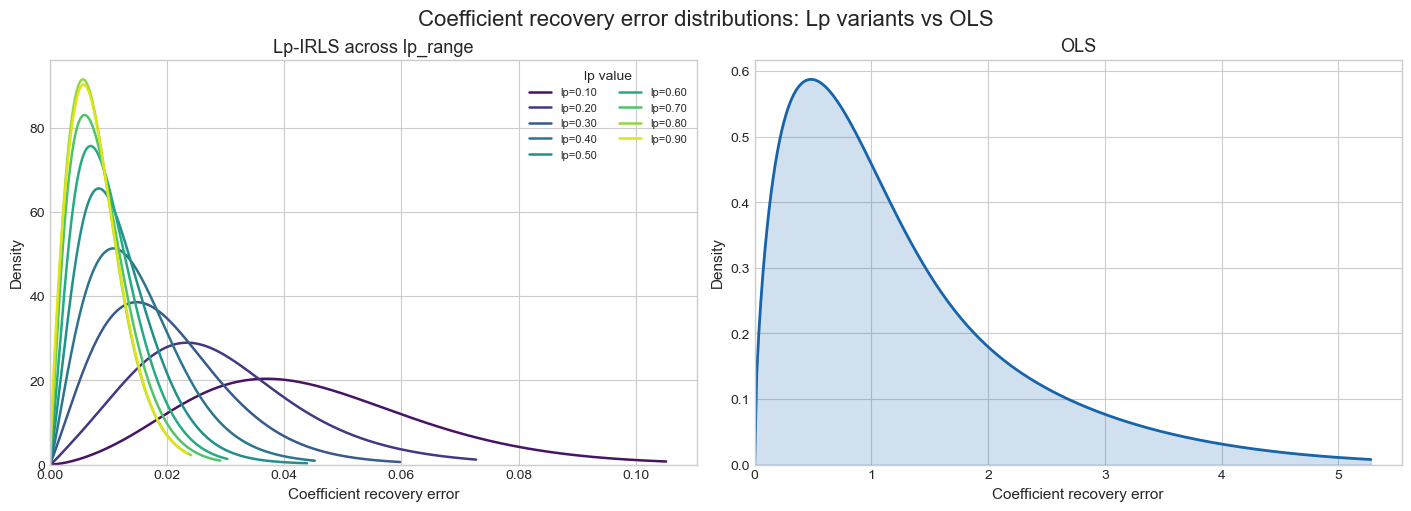

In [10]:
fig, (ax_lp, ax_ols) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
fig.suptitle(
    "Coefficient recovery error distributions: Lp variants vs OLS", fontsize=16
)

# ---- Left panel: one gamma KDE curve per lp value ----
lp_colors = plt.get_cmap("viridis")(np.linspace(0.05, 0.95, len(lp_range)))
for lp_index, lp in enumerate(lp_range):
    values = statistics["Lp-IRLS"]["Coefficient recovery error"][lp_index]
    x_grid, density = gamma_kde(values)
    ax_lp.plot(
        x_grid,
        density,
        color=lp_colors[lp_index],
        linewidth=1.8,
        label=f"lp={lp:.2f}",
    )

ax_lp.set_title("Lp-IRLS across lp_range", fontsize=13)
ax_lp.set_xlabel("Coefficient recovery error", fontsize=11)
ax_lp.set_ylabel("Density", fontsize=11)
ax_lp.set_xlim(left=0)
ax_lp.set_ylim(bottom=0)
ax_lp.legend(fontsize=8, ncol=2, title="lp value")

# ---- Right panel: OLS gamma KDE ----
ols_values = statistics["OLS"]["Coefficient recovery error"][0]
x_grid, density = gamma_kde(ols_values)
ols_color = plt.get_cmap("Blues")(0.8)
ax_ols.plot(x_grid, density, color=ols_color, linewidth=2)
ax_ols.fill_between(x_grid, density, color=ols_color, alpha=0.2)

ax_ols.set_title("OLS", fontsize=13)
ax_ols.set_xlabel("Coefficient recovery error", fontsize=11)
ax_ols.set_ylabel("Density", fontsize=11)
ax_ols.set_xlim(left=0)
ax_ols.set_ylim(bottom=0)

plt.show()